[INFO] Файл 'Lab_3_5.mat' успішно знайдено. Завантаження сигналу...

1. ІНФОРМАЦІЯ ПРО ВЕЙВЛЕТ (аналог waveinfo('coif4'))
Сімейство вейвлетів : Coiflets (coif4)
Порядок та довжина  : Порядок = 4, Довжина фільтра = 24 коеф.
Ортогональність     : True
Біортогональність   : True
Симетрія            : near symmetric


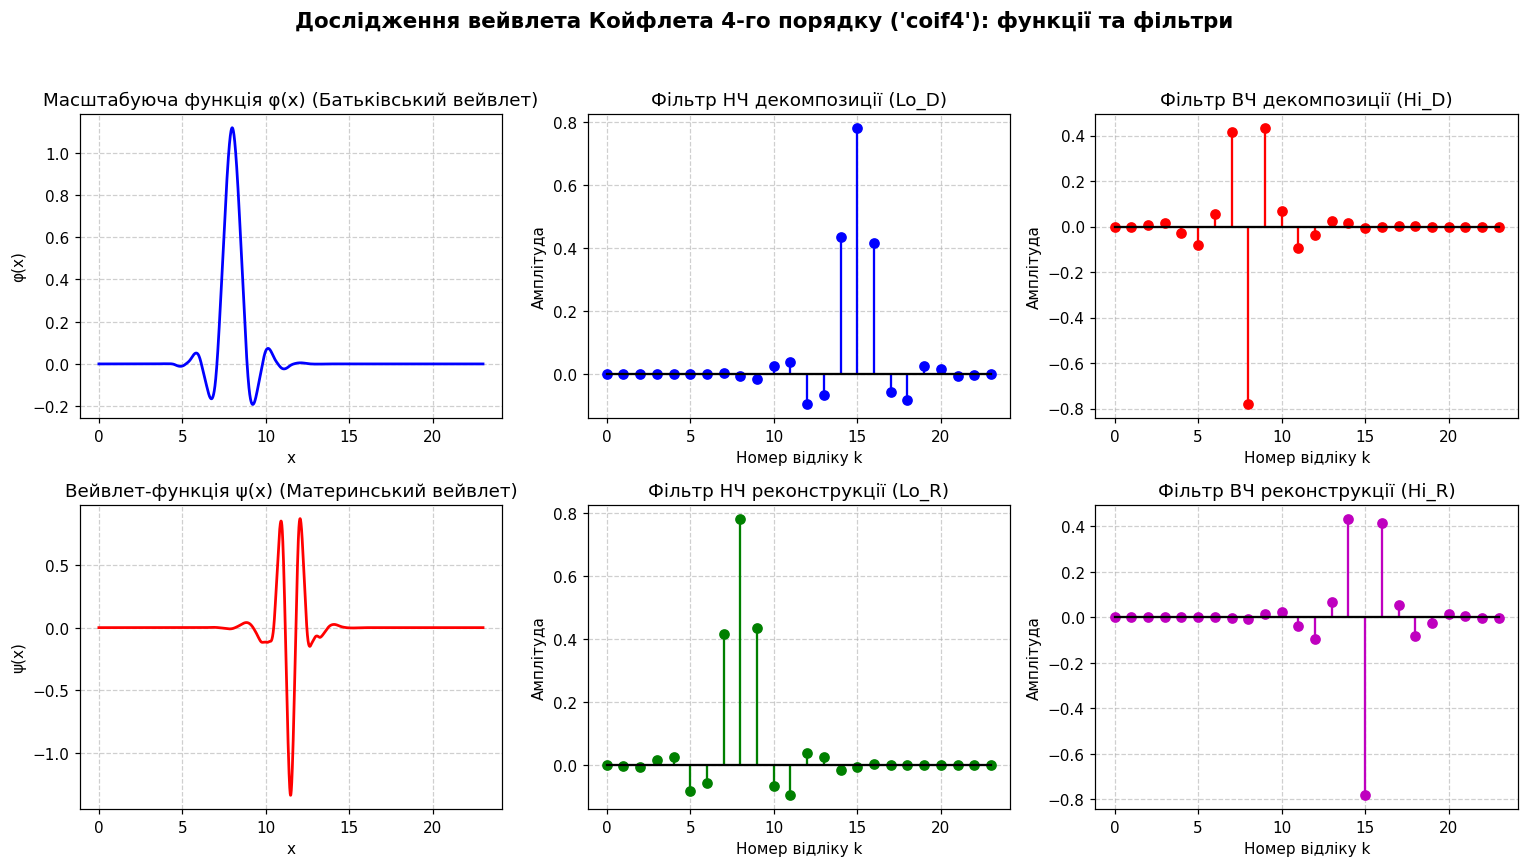


2. СТРУКТУРА ВЕЙВЛЕТ-РОЗКЛАДУ [C, L] (аналог wavedec, appcoef, detcoef)
Довжина вхідного сигналу s         : 1024 відліків
Загальна довжина вектора C         : 1092 коефіцієнтів
Вектор довжин L = [cA3, cD3, cD2, cD1, s] : [148, 148, 273, 523, 1024]
  -> Довжина cA3 (рівень 3, апрокс.): 148
  -> Довжина cD3 (рівень 3, детал.) : 148
  -> Довжина cD2 (рівень 2, детал.) : 273
  -> Довжина cD1 (рівень 1, детал.) : 523
Похибка перевірки тотожності |S - (A3+D3+D2+D1)| : 1.78e-14


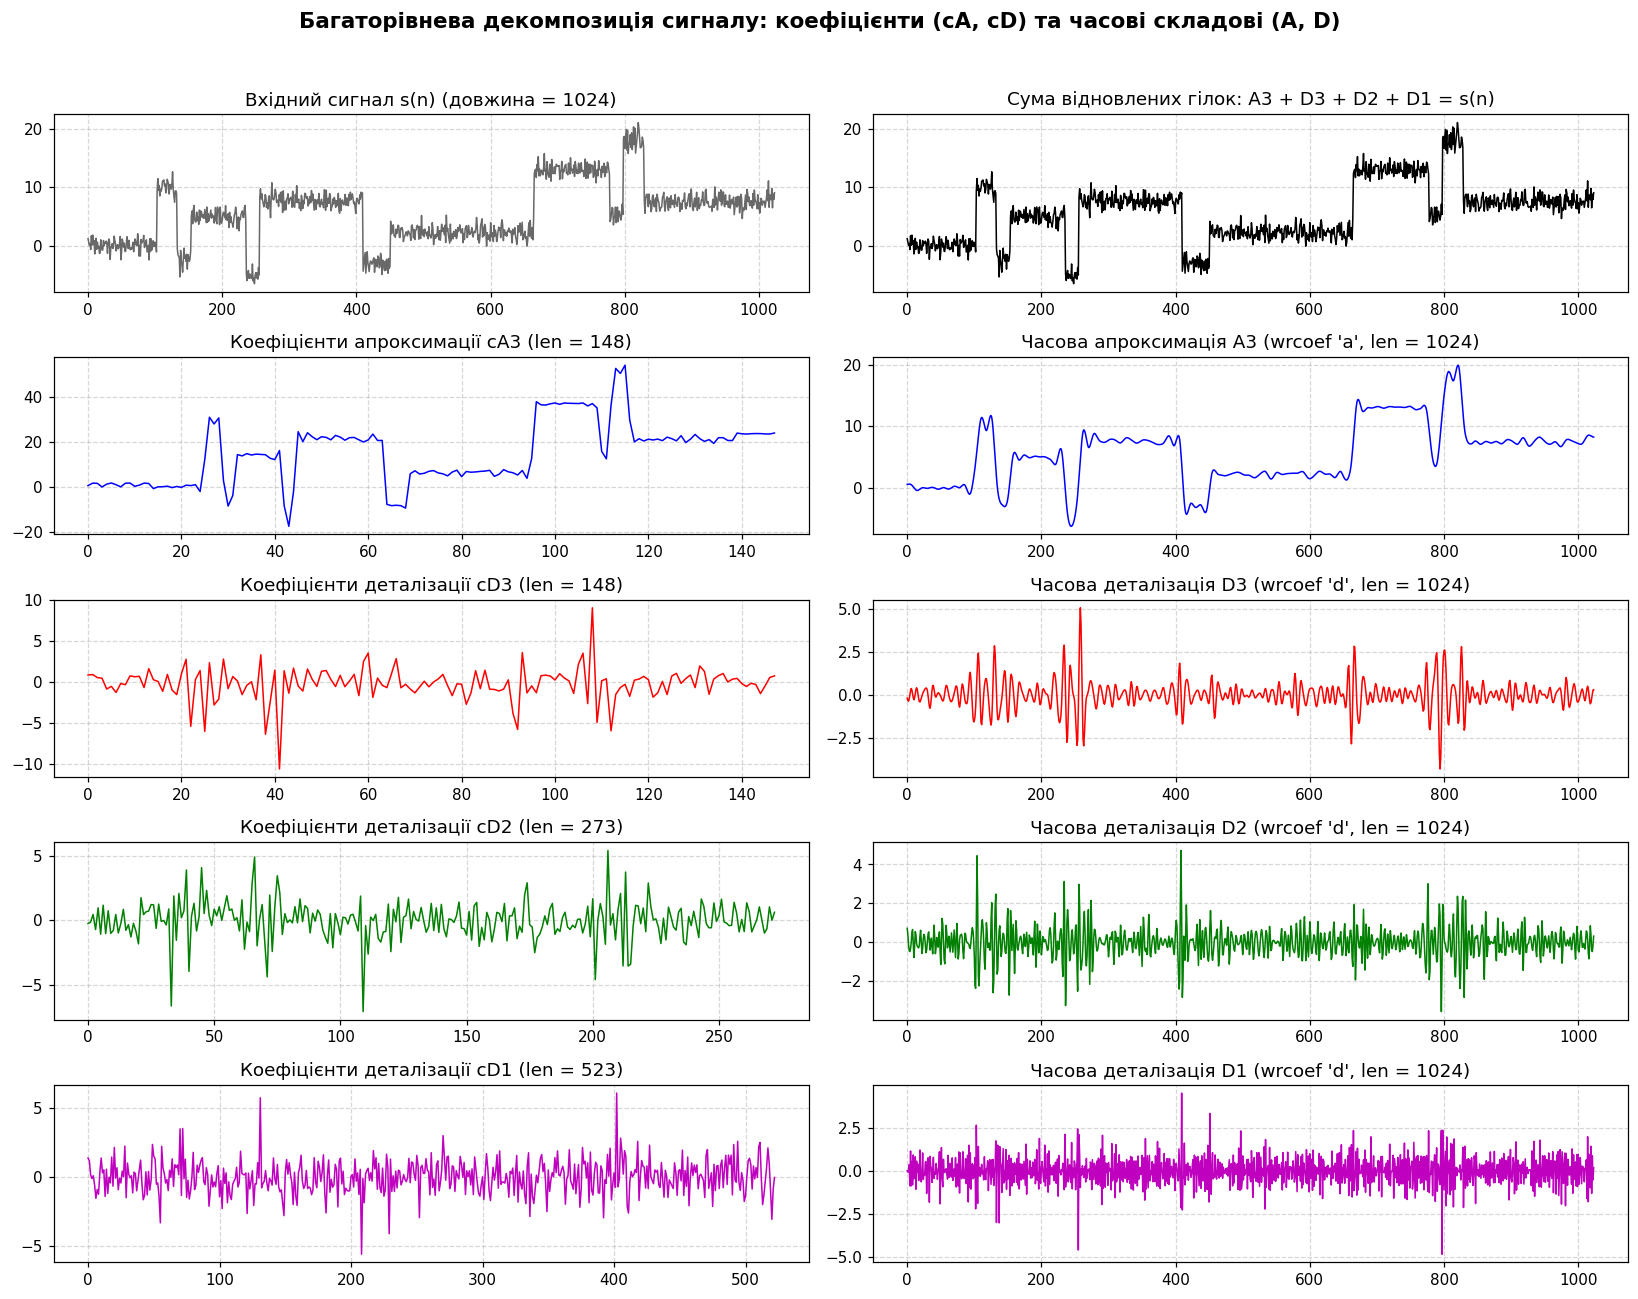


3. ПОРОГОВА ОБРОБКА ДЕТАЛІЗУЮЧИХ КОЕФІЦІЄНТІВ (sqtwolog, soft, Тип 2)
Рівень cD3 (n=148): stdc = 1.2646 | thr_base = 3.1614 | Поріг τ_3 = 3.9978 | Обнулено: 140/148 (94.6%)
Рівень cD2 (n=273): stdc = 1.2355 | thr_base = 3.3495 | Поріг τ_2 = 4.1382 | Обнулено: 267/273 (97.8%)
Рівень cD1 (n=523): stdc = 1.1132 | thr_base = 3.5382 | Поріг τ_1 = 3.9387 | Обнулено: 519/523 (99.2%)


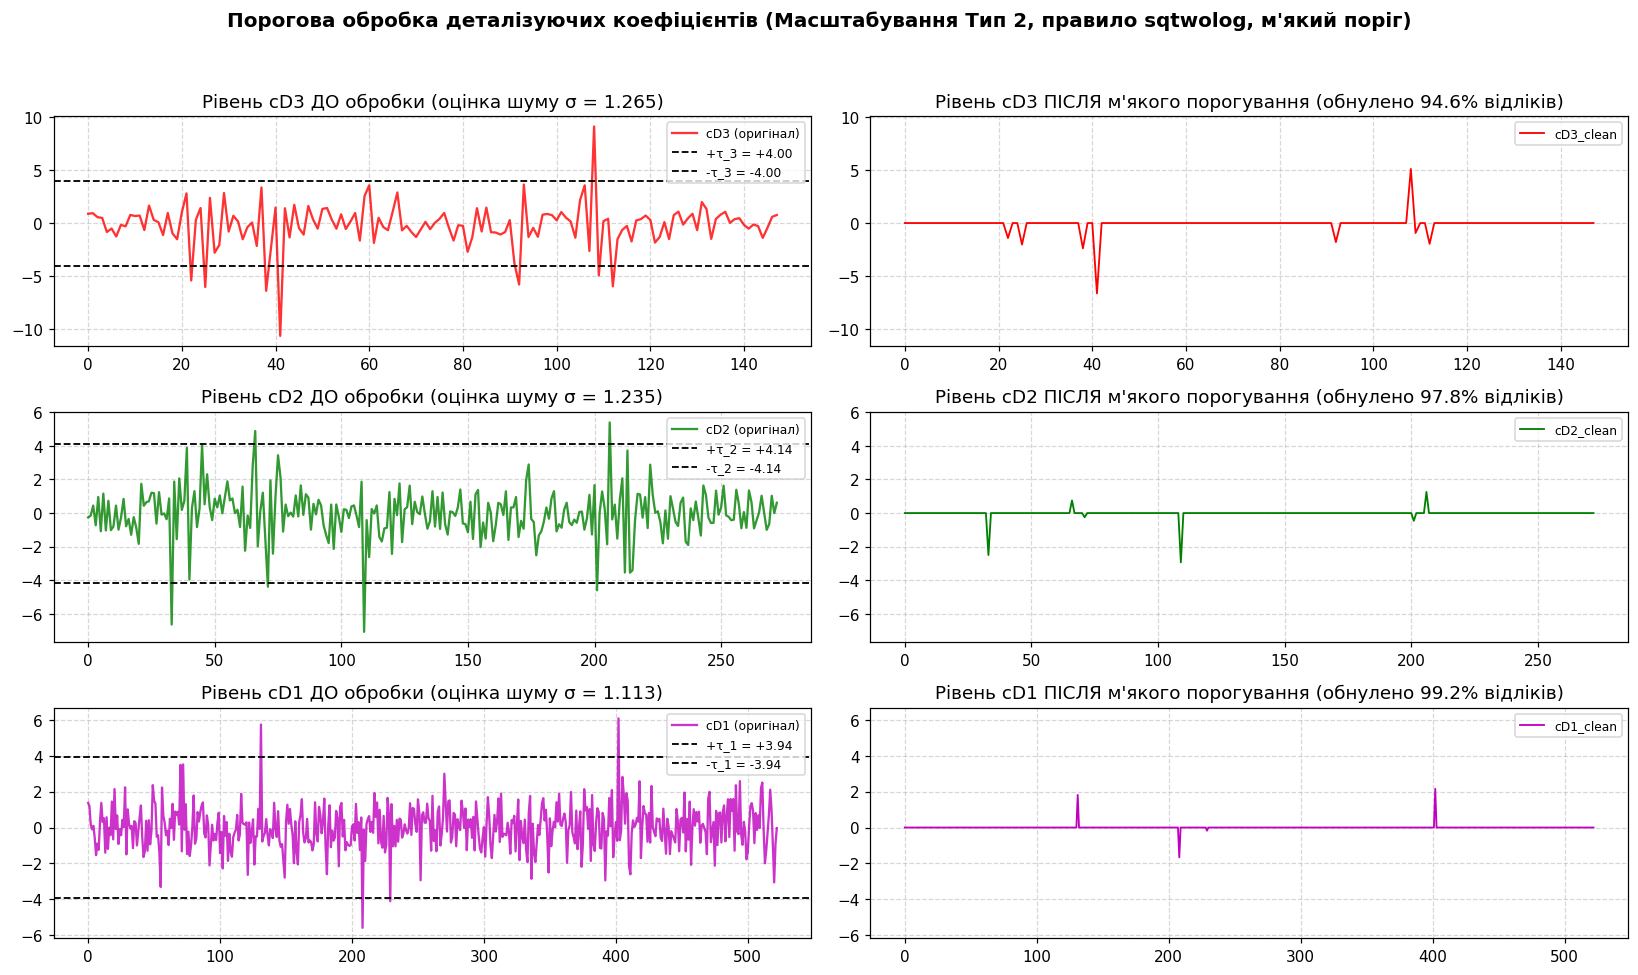


4. РЕЗУЛЬТАТИ РЕКОНСТРУКЦІЇ ТА ОЦІНКА ЕФЕКТИВНОСТІ ОЧИЩЕННЯ
СКВ (стандартне відхилення) вхідного сигналу    : 5.0834
СКВ (стандартне відхилення) очищеного сигналу   : 4.9038
СКВ відфільтрованої шумової компоненти e(n)     : 1.2282
Оцінка відношення Сигнал/Шум (SNR) після обробки: 15.63 дБ


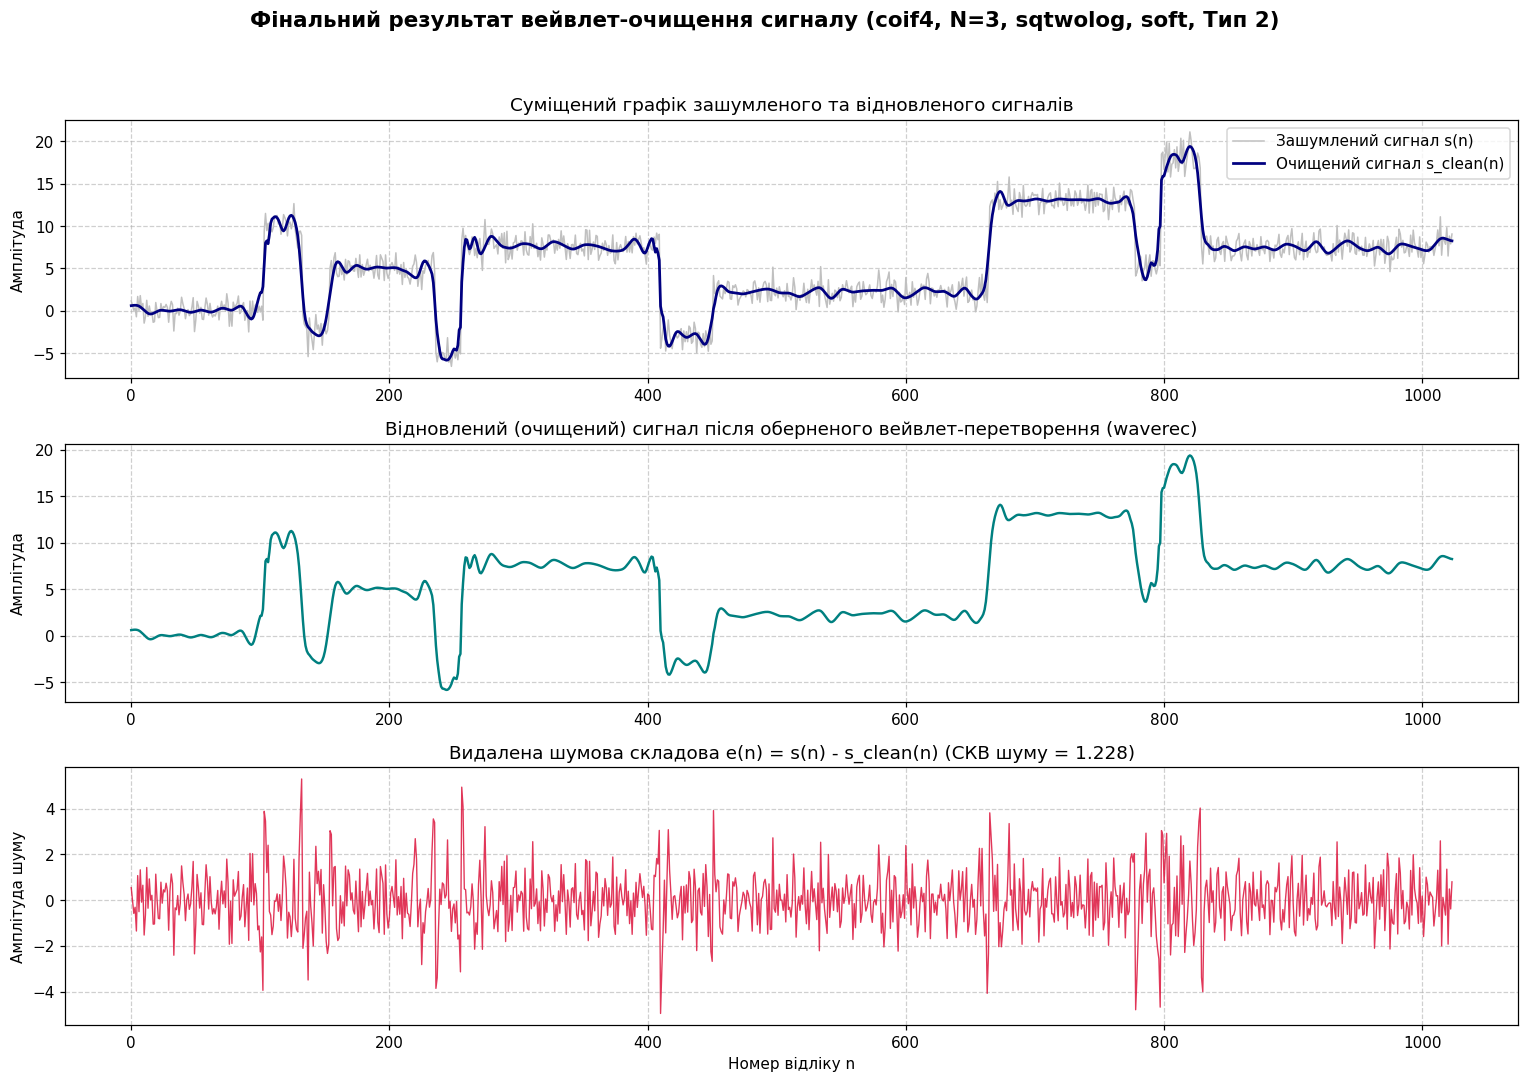

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy.io import loadmat

# ==============================================================================
# 1. ЗАВАНТАЖЕННЯ СИГНАЛУ ТА НАЛАШТУВАННЯ ВАРІАНТА 5
# ==============================================================================
for fname in ['Lab_5_5.mat', 'Lab_3_5.mat']:
    if os.path.exists(fname):
        filename = fname
        break
else:
    filename = None

if filename is not None:
    print(f"[INFO] Файл '{filename}' успішно знайдено. Завантаження сигналу...")
    data = loadmat(filename)
    s = data['signal'].flatten().astype(float)
else:
    print("[WARN] .mat файл не знайдено. Генерація тестового сигналу...")
    np.random.seed(42)
    t = np.linspace(0, 1, 1024)
    blocks = np.zeros_like(t)
    jumps = [0.1, 0.13, 0.15, 0.23, 0.25, 0.40, 0.44, 0.65, 0.76, 0.78, 0.81]
    heights = [10, -5, 5, -5, 8, -4, 2, 12, 5, 18, 8]
    for j, h in zip(jumps, heights):
        blocks[t >= j] = h
    s = blocks + 1.2 * np.random.randn(len(t))

N_samples = len(s)
wname = 'coif4'      # Койфлет 4-го порядку (Варіант 5)
level = 3
tptr = 'sqtwolog'
sorh = 'soft'
scal_type = 'Тип 2'

# ==============================================================================
# 2. ДОСЛІДЖЕННЯ ВЕЙВЛЕТА: waveinfo, wavefun, wfilters
# ==============================================================================
wavelet = pywt.Wavelet(wname)

print("\n" + "=" * 70)
print(f"1. ІНФОРМАЦІЯ ПРО ВЕЙВЛЕТ (аналог waveinfo('{wname}'))")
print("=" * 70)
print(f"Сімейство вейвлетів : {wavelet.family_name} ({wavelet.name})")
print(f"Порядок та довжина  : Порядок = 4, Довжина фільтра = {wavelet.dec_len} коеф.")
print(f"Ортогональність     : {wavelet.orthogonal}")
print(f"Біортогональність   : {wavelet.biorthogonal}")
print(f"Симетрія            : {wavelet.symmetry}")

# Отримання фільтрів Маллата (аналог [Lo_D, Hi_D, Lo_R, Hi_R] = wfilters('coif4'))
Lo_D = np.array(wavelet.dec_lo)
Hi_D = np.array(wavelet.dec_hi)
Lo_R = np.array(wavelet.rec_lo)
Hi_R = np.array(wavelet.rec_hi)

# Обчислення скейлінг-функції phi(x) та вейвлета psi(x) (аналог wavefun('coif4', 8))
phi, psi, x_grid = wavelet.wavefun(level=8)

# --- ГРАФІК 1: Властивості вейвлета coif4 та фільтри Маллата ---
fig1 = plt.figure(figsize=(14, 8), dpi=110)
fig1.suptitle(f"Дослідження вейвлета Койфлета 4-го порядку ('{wname}'): функції та фільтри",
              fontsize=14, fontweight='bold')

ax_phi = plt.subplot(2, 3, 1)
ax_phi.plot(x_grid, phi, 'b-', linewidth=1.8)
ax_phi.set_title("Масштабуюча функція φ(x) (Батьківський вейвлет)")
ax_phi.set_xlabel("x")
ax_phi.set_ylabel("φ(x)")
ax_phi.grid(True, linestyle='--', alpha=0.6)

ax_psi = plt.subplot(2, 3, 4)
ax_psi.plot(x_grid, psi, 'r-', linewidth=1.8)
ax_psi.set_title("Вейвлет-функція ψ(x) (Материнський вейвлет)")
ax_psi.set_xlabel("x")
ax_psi.set_ylabel("ψ(x)")
ax_psi.grid(True, linestyle='--', alpha=0.6)

filters_data = [
    (Lo_D, "Фільтр НЧ декомпозиції (Lo_D)", 2, 'b'),
    (Hi_D, "Фільтр ВЧ декомпозиції (Hi_D)", 3, 'r'),
    (Lo_R, "Фільтр НЧ реконструкції (Lo_R)", 5, 'g'),
    (Hi_R, "Фільтр ВЧ реконструкції (Hi_R)", 6, 'm')
]
for f_coef, title, pos, col in filters_data:
    ax_f = plt.subplot(2, 3, pos)
    ax_f.stem(range(len(f_coef)), f_coef, linefmt=f'{col}-', markerfmt=f'{col}o', basefmt='k-')
    ax_f.set_title(title)
    ax_f.set_xlabel("Номер відліку k")
    ax_f.set_ylabel("Амплітуда")
    ax_f.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('lab5_1_wavelet_info.png', dpi=300)
plt.show()

# ==============================================================================
# 3. БАГАТОРІВНЕВА ДЕКОМПОЗИЦІЯ: wavedec, appcoef, detcoef, wrcoef
# ==============================================================================
# Розклад сигналу до рівня N=3: [cA3, cD3, cD2, cD1]
coeffs = pywt.wavedec(s, wname, level=level)
cA3, cD3, cD2, cD1 = coeffs

C_vector = np.concatenate(coeffs)
L_vector = [len(c) for c in coeffs] + [N_samples]

print("\n" + "=" * 70)
print("2. СТРУКТУРА ВЕЙВЛЕТ-РОЗКЛАДУ [C, L] (аналог wavedec, appcoef, detcoef)")
print("=" * 70)
print(f"Довжина вхідного сигналу s         : {N_samples} відліків")
print(f"Загальна довжина вектора C         : {len(C_vector)} коефіцієнтів")
print(f"Вектор довжин L = [cA3, cD3, cD2, cD1, s] : {L_vector}")
print(f"  -> Довжина cA3 (рівень 3, апрокс.): {len(cA3)}")
print(f"  -> Довжина cD3 (рівень 3, детал.) : {len(cD3)}")
print(f"  -> Довжина cD2 (рівень 2, детал.) : {len(cD2)}")
print(f"  -> Довжина cD1 (рівень 1, детал.) : {len(cD1)}")

# Аналог функції MATLAB wrcoef('a'/'d', C, L, wname, level):
# Відновлення окремих часових складових A3, D3, D2, D1 повної довжини (1024)
def wrcoef_branch(coeffs_list, wavelet_name, branch_idx, target_len):
    temp_coeffs = [np.zeros_like(c) for c in coeffs_list]
    temp_coeffs[branch_idx] = coeffs_list[branch_idx].copy()
    rec_branch = pywt.waverec(temp_coeffs, wavelet_name)
    return rec_branch[:target_len]

A3_time = wrcoef_branch(coeffs, wname, 0, N_samples)
D3_time = wrcoef_branch(coeffs, wname, 1, N_samples)
D2_time = wrcoef_branch(coeffs, wname, 2, N_samples)
D1_time = wrcoef_branch(coeffs, wname, 3, N_samples)

# Перевірка тотожності Маллата: S = A3 + D3 + D2 + D1
recon_check_err = np.max(np.abs(s - (A3_time + D3_time + D2_time + D1_time)))
print(f"Похибка перевірки тотожності |S - (A3+D3+D2+D1)| : {recon_check_err:.2e}")

# --- ГРАФІК 2: Коефіцієнти декомпозиції (ліворуч) та відновлені гілки wrcoef (праворуч) ---
fig2, axs2 = plt.subplots(5, 2, figsize=(15, 12), dpi=110)
fig2.suptitle("Багаторівнева декомпозиція сигналу: коефіцієнти (cA, cD) та часові складові (A, D)",
              fontsize=14, fontweight='bold')

# Верхній рядок: вхідний сигнал
axs2[0, 0].plot(s, color='dimgray', linewidth=1.0)
axs2[0, 0].set_title(f"Вхідний сигнал s(n) (довжина = {N_samples})")
axs2[0, 0].grid(True, linestyle='--', alpha=0.5)

axs2[0, 1].plot(A3_time + D3_time + D2_time + D1_time, color='black', linewidth=1.0)
axs2[0, 1].set_title("Сума відновлених гілок: A3 + D3 + D2 + D1 = s(n)")
axs2[0, 1].grid(True, linestyle='--', alpha=0.5)

left_items = [
    (cA3, f"Коефіцієнти апроксимації cA3 (len = {len(cA3)})", 'b'),
    (cD3, f"Коефіцієнти деталізації cD3 (len = {len(cD3)})", 'r'),
    (cD2, f"Коефіцієнти деталізації cD2 (len = {len(cD2)})", 'g'),
    (cD1, f"Коефіцієнти деталізації cD1 (len = {len(cD1)})", 'm')
]
right_items = [
    (A3_time, f"Часова апроксимація A3 (wrcoef 'a', len = {N_samples})", 'b'),
    (D3_time, f"Часова деталізація D3 (wrcoef 'd', len = {N_samples})", 'r'),
    (D2_time, f"Часова деталізація D2 (wrcoef 'd', len = {N_samples})", 'g'),
    (D1_time, f"Часова деталізація D1 (wrcoef 'd', len = {N_samples})", 'm')
]

for row_idx in range(4):
    coef_arr, l_title, col = left_items[row_idx]
    time_arr, r_title, _ = right_items[row_idx]

    axs2[row_idx + 1, 0].plot(coef_arr, color=col, linewidth=1.0)
    axs2[row_idx + 1, 0].set_title(l_title)
    axs2[row_idx + 1, 0].grid(True, linestyle='--', alpha=0.5)

    axs2[row_idx + 1, 1].plot(time_arr, color=col, linewidth=1.0)
    axs2[row_idx + 1, 1].set_title(r_title)
    axs2[row_idx + 1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('lab5_2_decomposition_tree.png', dpi=300)
plt.show()

# ==============================================================================
# 4. ПОРОГОВА ОБРОБКА: wnoisest (Тип 2), thselect ('sqtwolog'), М'який поріг
# ==============================================================================
clean_coeffs = [cA3.copy()]  # Коефіцієнти апроксимації cA3 не порогуються
thresholds_info = []

print("\n" + "=" * 70)
print(f"3. ПОРОГОВА ОБРОБКА ДЕТАЛІЗУЮЧИХ КОЕФІЦІЄНТІВ ({tptr}, {sorh}, {scal_type})")
print("=" * 70)

for i in range(1, level + 1):
    lvl_num = level - i + 1  # Рівень: 3, 2, 1
    cD_curr = coeffs[i]
    n_len = len(cD_curr)

    # Оцінка стандартного відхилення шуму на рівні (аналог stdc = wnoisest(C, L, i))
    stdc = np.median(np.abs(cD_curr)) / 0.6745

    thr_unscaled = np.sqrt(2.0 * np.log(n_len))

    thr_scaled = thr_unscaled * stdc

    cD_thresh = pywt.threshold(cD_curr, value=thr_scaled, mode=sorh)
    clean_coeffs.append(cD_thresh)

    # Підрахунок кількості обнулених коефіцієнтів
    zeroed_count = np.sum(np.abs(cD_thresh) == 0)
    zeroed_pct = 100.0 * zeroed_count / n_len

    thresholds_info.append((lvl_num, cD_curr, cD_thresh, stdc, thr_unscaled, thr_scaled, zeroed_pct))
    print(f"Рівень cD{lvl_num} (n={n_len:3d}): stdc = {stdc:.4f} | "
          f"thr_base = {thr_unscaled:.4f} | Поріг τ_{lvl_num} = {thr_scaled:.4f} | "
          f"Обнулено: {zeroed_count}/{n_len} ({zeroed_pct:.1f}%)")

# --- ГРАФІК 3: Наочне порівняння cD1, cD2, cD3 ДО та ПІСЛЯ порогування з лініями ±τ ---
fig3, axs3 = plt.subplots(3, 2, figsize=(15, 9), dpi=110)
fig3.suptitle("Порогова обробка деталізуючих коефіцієнтів (Масштабування Тип 2, правило sqtwolog, м'який поріг)",
              fontsize=13, fontweight='bold')

colors_lvl = {3: 'r', 2: 'g', 1: 'm'}
for idx, (lvl_num, cD_orig, cD_cln, stdc, _, thr_val, z_pct) in enumerate(thresholds_info):
    col = colors_lvl[lvl_num]

    # ДО порогування + коридор порогу ±τ
    axs3[idx, 0].plot(cD_orig, color=col, alpha=0.8, label=f'cD{lvl_num} (оригінал)')
    axs3[idx, 0].axhline(thr_val, color='k', linestyle='--', linewidth=1.2, label=f'+τ_{lvl_num} = +{thr_val:.2f}')
    axs3[idx, 0].axhline(-thr_val, color='k', linestyle='--', linewidth=1.2, label=f'-τ_{lvl_num} = -{thr_val:.2f}')
    axs3[idx, 0].set_title(f"Рівень cD{lvl_num} ДО обробки (оцінка шуму σ = {stdc:.3f})")
    axs3[idx, 0].legend(loc='upper right', fontsize=8)
    axs3[idx, 0].grid(True, linestyle='--', alpha=0.5)

    # ПІСЛЯ м'якого порогування
    axs3[idx, 1].plot(cD_cln, color=col, linewidth=1.2, label=f'cD{lvl_num}_clean')
    axs3[idx, 1].set_title(f"Рівень cD{lvl_num} ПІСЛЯ м'якого порогування (обнулено {z_pct:.1f}% відліків)")
    axs3[idx, 1].set_ylim(axs3[idx, 0].get_ylim())  # Однакова шкала Y для чесного порівняння
    axs3[idx, 1].legend(loc='upper right', fontsize=8)
    axs3[idx, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('lab5_3_thresholding_levels.png', dpi=300)
plt.show()

# ==============================================================================
# 5. ВЕЙВЛЕТ-РЕКОНСТРУКЦІЯ (waverec) ТА ОЦІНКА ЯКОСТІ ОЧИЩЕННЯ
# ==============================================================================
s_clean = pywt.waverec(clean_coeffs, wname)[:N_samples]
removed_noise = s - s_clean

# Статистичні метрики
std_orig = np.std(s)
std_clean = np.std(s_clean)
std_noise = np.std(removed_noise)
snr_est = 10.0 * np.log10(np.sum(s_clean ** 2) / np.sum(removed_noise ** 2))

print("\n" + "=" * 70)
print("4. РЕЗУЛЬТАТИ РЕКОНСТРУКЦІЇ ТА ОЦІНКА ЕФЕКТИВНОСТІ ОЧИЩЕННЯ")
print("=" * 70)
print(f"СКВ (стандартне відхилення) вхідного сигналу    : {std_orig:.4f}")
print(f"СКВ (стандартне відхилення) очищеного сигналу   : {std_clean:.4f}")
print(f"СКВ відфільтрованої шумової компоненти e(n)     : {std_noise:.4f}")
print(f"Оцінка відношення Сигнал/Шум (SNR) після обробки: {snr_est:.2f} дБ")
print("=" * 70)

# --- ГРАФІК 4: Фінальне порівняння сигналів та відфільтрований шум ---
fig4, axs4 = plt.subplots(3, 1, figsize=(14, 10), dpi=110)
fig4.suptitle(f"Фінальний результат вейвлет-очищення сигналу ({wname}, N={level}, {tptr}, {sorh}, {scal_type})",
              fontsize=14, fontweight='bold')

# 1. Зашумлений vs Очищений (накладання)
axs4[0].plot(s, color='silver', linewidth=1.0, label='Зашумлений сигнал s(n)')
axs4[0].plot(s_clean, color='navy', linewidth=1.8, label='Очищений сигнал s_clean(n)')
axs4[0].set_title("Суміщений графік зашумленого та відновленого сигналів")
axs4[0].set_ylabel("Амплітуда")
axs4[0].legend(loc='upper right')
axs4[0].grid(True, linestyle='--', alpha=0.6)

# 2. Чистий відновлений сигнал окремо
axs4[1].plot(s_clean, color='teal', linewidth=1.6)
axs4[1].set_title("Відновлений (очищений) сигнал після оберненого вейвлет-перетворення (waverec)")
axs4[1].set_ylabel("Амплітуда")
axs4[1].grid(True, linestyle='--', alpha=0.6)

# 3. Відфільтрований шум e(n) = s(n) - s_clean(n)
axs4[2].plot(removed_noise, color='crimson', linewidth=0.9, alpha=0.85)
axs4[2].set_title(f"Видалена шумова складова e(n) = s(n) - s_clean(n) (СКВ шуму = {std_noise:.3f})")
axs4[2].set_xlabel("Номер відліку n")
axs4[2].set_ylabel("Амплітуда шуму")
axs4[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('lab5_4_final_denoising.png', dpi=300)
plt.show()